In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, cohen_kappa_score,
    matthews_corrcoef
)
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/MangoProject/Models/

best_ConNext_fruit.pth		best_model.pth
best_efficientnet_b0_fruit.pth	best_resnet_18_fruit.pth
best_efficientnet_b0_leaf.pth	best_resNet18_leaf.pth
best_mobilenet_v2_fruit.pth	best_resnet50_fruit.pth
best_mobilenet_v2_leaf.pth	best_resNet50_leaf.pth


In [ ]:
IMG_SIZE = 224
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

def get_aligned_image_pairs(leaf_dir, fruit_dir):
    pairs = []
    for class_name in sorted(os.listdir(leaf_dir)):
        leaf_class_path = os.path.join(leaf_dir, class_name)
        fruit_class_path = os.path.join(fruit_dir, class_name)
        leaf_images = sorted(os.listdir(leaf_class_path))
        fruit_images = sorted(os.listdir(fruit_class_path))

        min_len = min(len(leaf_images), len(fruit_images))
        for i in range(min_len):
            leaf_path = os.path.join(leaf_class_path, leaf_images[i])
            fruit_path = os.path.join(fruit_class_path, fruit_images[i])
            pairs.append((leaf_path, fruit_path, class_name))
    return pairs

class PairedDataset(Dataset):
    def __init__(self, pairs, transform_leaf=None, transform_fruit=None, class_to_idx=None):
        self.pairs = pairs
        self.transform_leaf = transform_leaf
        self.transform_fruit = transform_fruit
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        leaf_path, fruit_path, label_str = self.pairs[idx]
        leaf_img = Image.open(leaf_path).convert('RGB')
        fruit_img = Image.open(fruit_path).convert('RGB')

        if self.transform_leaf:
            leaf_img = self.transform_leaf(leaf_img)
        if self.transform_fruit:
            fruit_img = self.transform_fruit(fruit_img)

        label = self.class_to_idx[label_str]
        return leaf_img, fruit_img, label


In [ ]:
# Define directories where the data is stored
leaf_val_dir = "/content/drive/MyDrive/datasets/Split_Leaves/val"
fruit_val_dir = "/content/drive/MyDrive/datasets/Mango/Split_Fruits/val"

# Setting up paired loader
val_pairs = get_aligned_image_pairs(leaf_val_dir, fruit_val_dir)
class_to_idx = {cls_name: idx for idx, cls_name in enumerate(sorted(os.listdir(leaf_val_dir)))}
paired_val_ds = PairedDataset(val_pairs, val_transform, val_transform, class_to_idx)
paired_val_loader = DataLoader(paired_val_ds, batch_size=32, shuffle=False)


In [ ]:

def get_model(name, num_classes=4):
    if name == "resnet18":
        model = models.resnet18(pretrained=False)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(pretrained=False)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif name == "mobilenet_v2":
        model = models.mobilenet_v2(pretrained=False)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif name == "resnet50":
        model = models.resnet50(pretrained=False)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif name == "convnext_tiny":
        model = models.convnext_tiny(pretrained=False)
        model.classifier[2] = nn.Linear(model.classifier[2].in_features, num_classes)

    # Optional: Add more variants like convnext_small, convnext_base if needed
    return model

In [ ]:



num_classes = 4
leaf_model = get_model(num_classes).to(device)
fruit_model = get_model(num_classes).to(device)

leaf_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_resNet18_leaf.pth", map_location=device))
fruit_model.load_state_dict(torch.load("/content/drive/MyDrive/MangoProject/Models/best_resnet_18_fruit.pth", map_location=device))

leaf_model.eval()
fruit_model.eval()


In [ ]:
class ModalityAttention(nn.Module):
    def __init__(self, num_classes):
        super(ModalityAttention, self).__init__()
        self.attn_fc = nn.Sequential(
            nn.Linear(num_classes * 2, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
            nn.Softmax(dim=1)
        )

    def forward(self, leaf_logits, fruit_logits):
        x = torch.cat([leaf_logits, fruit_logits], dim=1)
        weights = self.attn_fc(x)
        leaf_weight, fruit_weight = weights[:, 0].unsqueeze(1), weights[:, 1].unsqueeze(1)
        fused_logits = leaf_weight * leaf_logits + fruit_weight * fruit_logits
        return fused_logits, weights


In [ ]:
class FusionModel(nn.Module):
    def __init__(self, leaf_model, fruit_model, num_classes=4):
        super(FusionModel, self).__init__()
        self.leaf_model = leaf_model
        self.fruit_model = fruit_model
        self.attn = ModalityAttention(num_classes)

    def forward(self, leaf_input, fruit_input):
        leaf_logits = self.leaf_model(leaf_input)
        fruit_logits = self.fruit_model(fruit_input)
        fused_logits, attn_weights = self.attn(leaf_logits, fruit_logits)
        return fused_logits, attn_weights


In [ ]:
# Initialize fusion model
fusion_model = FusionModel(leaf_model, fruit_model).to(device)


In [ ]:
def evaluate_attention_fusion(fusion_model, dataloader, device, class_names=None, model_name="FusionModel"):
    fusion_model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for leaf_imgs, fruit_imgs, labels in dataloader:
            leaf_imgs, fruit_imgs = leaf_imgs.to(device), fruit_imgs.to(device)
            labels = labels.to(device)

            outputs, _ = fusion_model(leaf_imgs, fruit_imgs)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    print(f"\n📌 Evaluating Model: {model_name}")
    print(f"✅ Accuracy: {accuracy_score(all_labels, all_preds):.4f}")
    print(f"🔁 Precision (macro): {precision_score(all_labels, all_preds, average='macro'):.4f}")
    print(f"🔁 Recall (macro): {recall_score(all_labels, all_preds, average='macro'):.4f}")
    print(f"🔁 F1 Score (macro): {f1_score(all_labels, all_preds, average='macro'):.4f}")
    print(f"🧠 Cohen’s Kappa: {cohen_kappa_score(all_labels, all_preds):.4f}")
    print(f"🧠 Matthews Corrcoef: {matthews_corrcoef(all_labels, all_preds):.4f}")

    print("\n📊 Classification Report:\n")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


In [ ]:
def visualize_attention_weights(fusion_model, val_loader, model_name="FusionModel", num_samples=50):
    fusion_model.eval()
    attn_data = []

    with torch.no_grad():
        for i, (leaf_imgs, fruit_imgs, _) in enumerate(val_loader):
            leaf_imgs, fruit_imgs = leaf_imgs.to(device), fruit_imgs.to(device)
            _, attn_weights = fusion_model(leaf_imgs, fruit_imgs)
            attn_data.extend(attn_weights.cpu().numpy())

            if len(attn_data) >= num_samples:
                break

    attn_data = np.array(attn_data[:num_samples])
    plt.figure(figsize=(10, 4))
    plt.plot(attn_data[:, 0], label='Leaf Attention', marker='o')
    plt.plot(attn_data[:, 1], label='Fruit Attention', marker='x')
    plt.title(f"Attention Weights - {model_name}")
    plt.xlabel("Sample Index")
    plt.ylabel("Attention Weight")
    plt.legend()
    plt.grid(True)
    plt.show()


In [ ]:
import pandas as pd

def attention_boxplot(fusion_model, val_loader, model_name="FusionModel", num_samples=100):
    fusion_model.eval()
    attn_data = []

    with torch.no_grad():
        for i, (leaf_imgs, fruit_imgs, _) in enumerate(val_loader):
            leaf_imgs, fruit_imgs = leaf_imgs.to(device), fruit_imgs.to(device)
            _, attn_weights = fusion_model(leaf_imgs, fruit_imgs)
            attn_data.extend(attn_weights.cpu().numpy())

            if len(attn_data) >= num_samples:
                break

    attn_data = np.array(attn_data[:num_samples])
    df = pd.DataFrame(attn_data, columns=["Leaf", "Fruit"])

    plt.figure(figsize=(6, 5))
    sns.boxplot(data=df)
    plt.title(f"Attention Weight Distribution - {model_name}")
    plt.ylabel("Attention Weight")
    plt.grid(True)
    plt.show()


In [ ]:
def stacked_attention_plot(fusion_model, val_loader, model_name="FusionModel", num_samples=50):
    fusion_model.eval()
    attn_data = []

    with torch.no_grad():
        for i, (leaf_imgs, fruit_imgs, _) in enumerate(val_loader):
            leaf_imgs, fruit_imgs = leaf_imgs.to(device), fruit_imgs.to(device)
            _, attn_weights = fusion_model(leaf_imgs, fruit_imgs)
            attn_data.extend(attn_weights.cpu().numpy())

            if len(attn_data) >= num_samples:
                break

    attn_data = np.array(attn_data[:num_samples])
    plt.figure(figsize=(10, 4))
    plt.stackplot(range(num_samples), attn_data[:, 0], attn_data[:, 1], labels=['Leaf', 'Fruit'])
    plt.title(f"Stacked Attention Areas - {model_name}")
    plt.xlabel("Sample Index")
    plt.ylabel("Attention Weight")
    plt.legend()
    plt.grid(True)
    plt.show()



📌 Evaluating Model: ResNet18 Fusion
✅ Accuracy: 0.9862
🔁 Precision (macro): 0.9797
🔁 Recall (macro): 0.9861
🔁 F1 Score (macro): 0.9823
🧠 Cohen’s Kappa: 0.9805
🧠 Matthews Corrcoef: 0.9807

📊 Classification Report:

                      precision    recall  f1-score   support

         Anthracnose       0.92      1.00      0.96        34
Bacterial_Black_Spot       1.00      0.94      0.97        54
             Healthy       1.00      1.00      1.00        37
            Multiple       1.00      1.00      1.00        93

            accuracy                           0.99       218
           macro avg       0.98      0.99      0.98       218
        weighted avg       0.99      0.99      0.99       218



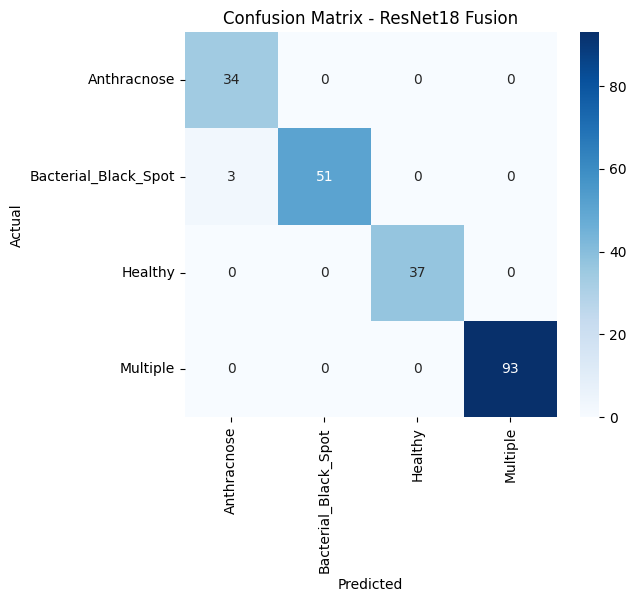

In [ ]:
class_names = ["Anthracnose", "Bacterial_Black_Spot", "Healthy", "Multiple"]

evaluate_attention_fusion(fusion_model, paired_val_loader, device, class_names, model_name="ResNet18 Fusion")



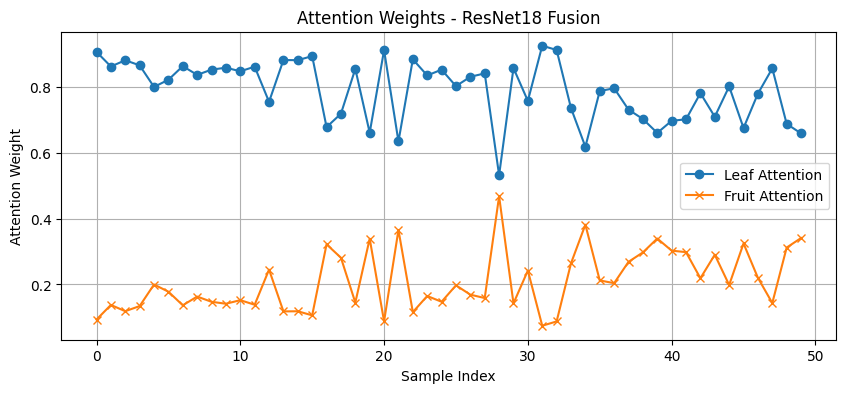

In [ ]:
visualize_attention_weights(fusion_model, paired_val_loader, model_name="ResNet18 Fusion")

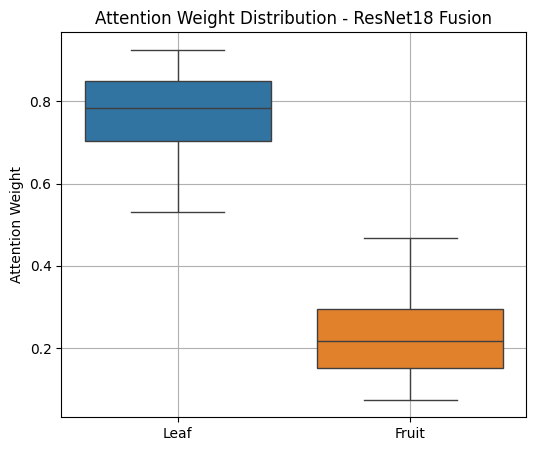

In [ ]:
attention_boxplot(fusion_model, paired_val_loader, model_name="ResNet18 Fusion")


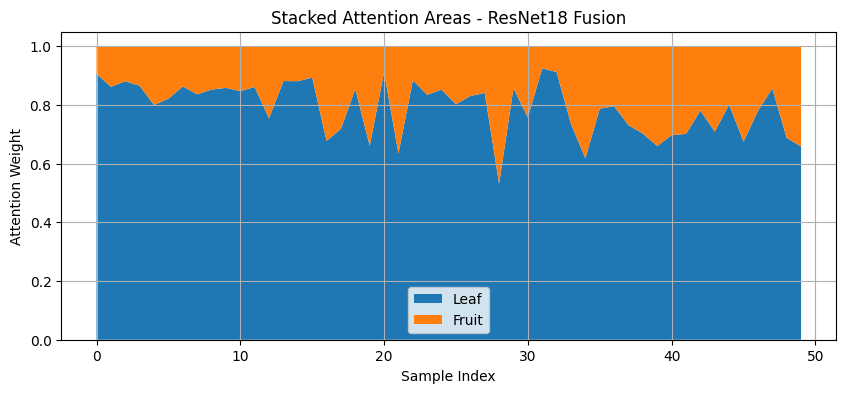

In [ ]:
stacked_attention_plot(fusion_model, paired_val_loader, model_name="ResNet18 Fusion")


In [ ]:
leaf_model_path = "/content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_leaf.pth"
fruit_model_path = "/content/drive/MyDrive/MangoProject/Models/best_efficientnet_b0_fruit.pth"
model_name = "EfficientNet-B0 Fusion"


In [ ]:
leaf_model = get_model("efficientnet_b0").to(device)
fruit_model = get_model("efficientnet_b0").to(device)

leaf_model.load_state_dict(torch.load(leaf_model_path, map_location=device))
fruit_model.load_state_dict(torch.load(fruit_model_path, map_location=device))

leaf_model.eval()
fruit_model.eval()


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
fusion_model = FusionModel(leaf_model, fruit_model).to(device)



📌 Evaluating Model: EfficientNet-B0 Fusion
✅ Accuracy: 0.9954
🔁 Precision (macro): 0.9973
🔁 Recall (macro): 0.9954
🔁 F1 Score (macro): 0.9963
🧠 Cohen’s Kappa: 0.9935
🧠 Matthews Corrcoef: 0.9935

📊 Classification Report:

                      precision    recall  f1-score   support

         Anthracnose       1.00      1.00      1.00        34
Bacterial_Black_Spot       1.00      0.98      0.99        54
             Healthy       1.00      1.00      1.00        37
            Multiple       0.99      1.00      0.99        93

            accuracy                           1.00       218
           macro avg       1.00      1.00      1.00       218
        weighted avg       1.00      1.00      1.00       218



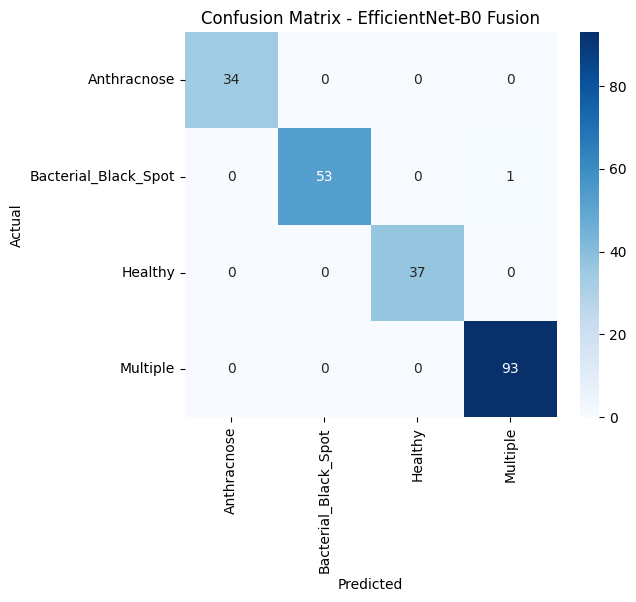

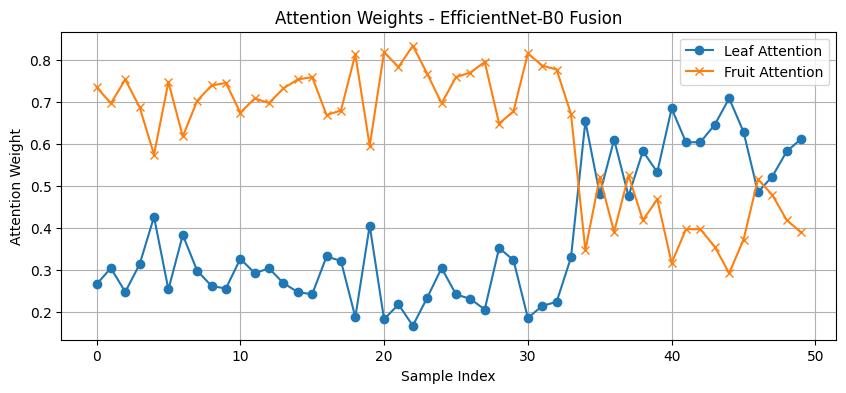

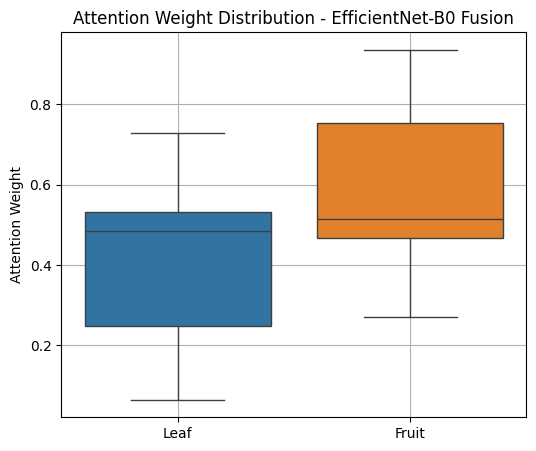

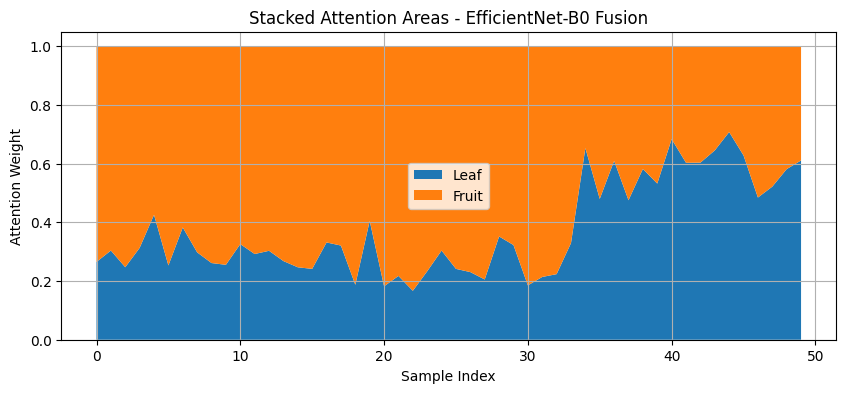

In [ ]:
evaluate_attention_fusion(fusion_model, paired_val_loader, device, class_names, model_name=model_name)
visualize_attention_weights(fusion_model, paired_val_loader, model_name=model_name)
attention_boxplot(fusion_model, paired_val_loader, model_name=model_name)
stacked_attention_plot(fusion_model, paired_val_loader, model_name=model_name)


In [ ]:
# Step 1: Set paths and name
leaf_model_path = "/content/drive/MyDrive/MangoProject/Models/best_resNet50_leaf.pth"
fruit_model_path = "/content/drive/MyDrive/MangoProject/Models/best_resnet50_fruit.pth"
model_name = "ResNet50 Fusion"

In [ ]:
leaf_model = get_model("resnet50").to(device)
fruit_model = get_model("resnet50").to(device)

leaf_model.load_state_dict(torch.load(leaf_model_path, map_location=device))
fruit_model.load_state_dict(torch.load(fruit_model_path, map_location=device))

leaf_model.eval()
fruit_model.eval()

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  w

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
fusion_model = FusionModel(leaf_model, fruit_model).to(device)



📌 Evaluating Model: ResNet50 Fusion
✅ Accuracy: 0.9954
🔁 Precision (macro): 0.9929
🔁 Recall (macro): 0.9954
🔁 F1 Score (macro): 0.9940
🧠 Cohen’s Kappa: 0.9935
🧠 Matthews Corrcoef: 0.9935

📊 Classification Report:

                      precision    recall  f1-score   support

         Anthracnose       0.97      1.00      0.99        34
Bacterial_Black_Spot       1.00      0.98      0.99        54
             Healthy       1.00      1.00      1.00        37
            Multiple       1.00      1.00      1.00        93

            accuracy                           1.00       218
           macro avg       0.99      1.00      0.99       218
        weighted avg       1.00      1.00      1.00       218



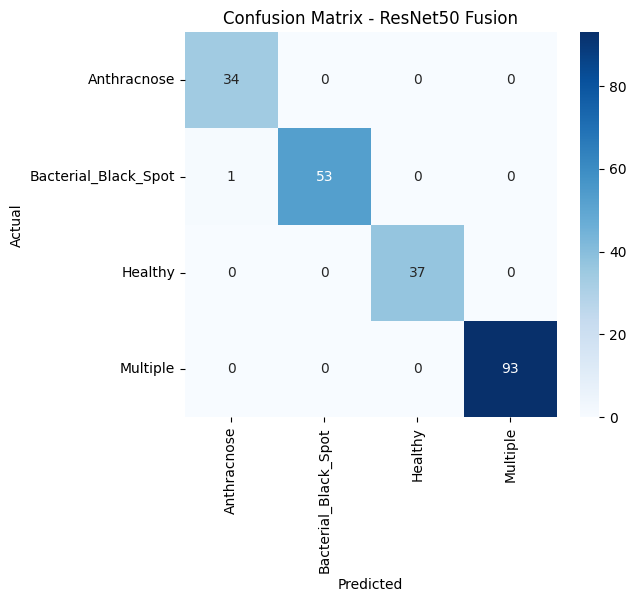

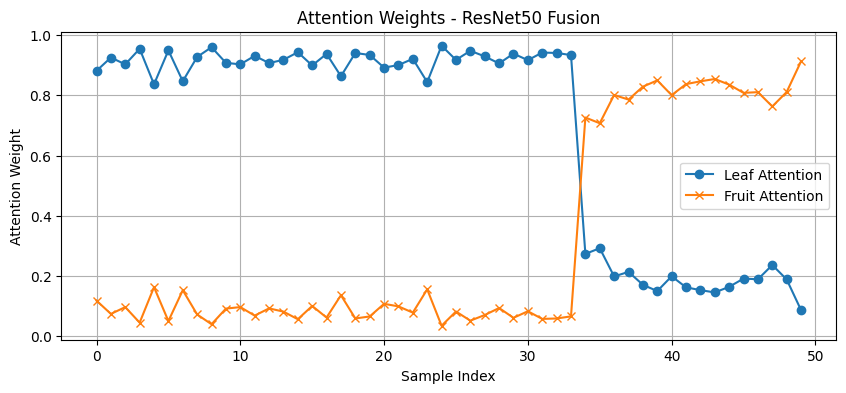

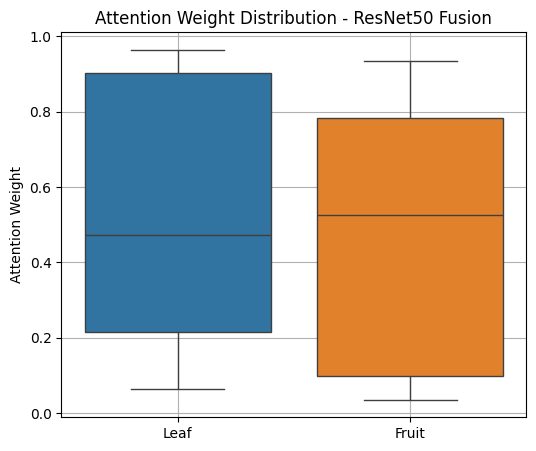

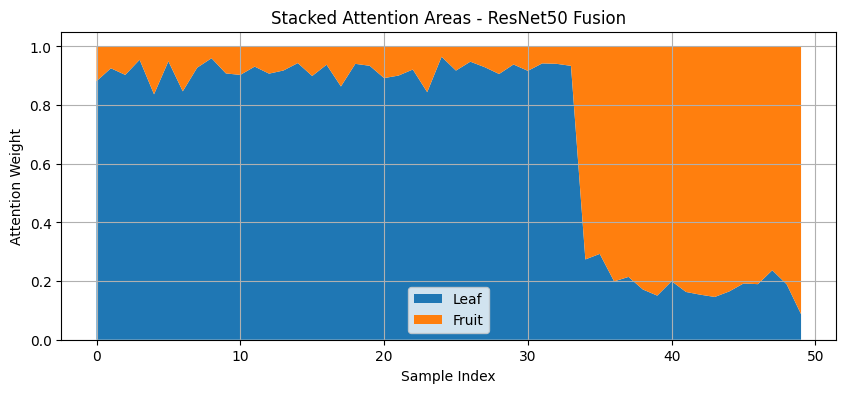

In [ ]:
# Step 4: Run evaluation + visualization
evaluate_attention_fusion(fusion_model, paired_val_loader, device, class_names, model_name=model_name)
visualize_attention_weights(fusion_model, paired_val_loader, model_name=model_name)
attention_boxplot(fusion_model, paired_val_loader, model_name=model_name)
stacked_attention_plot(fusion_model, paired_val_loader, model_name=model_name)

In [ ]:
leaf_model_path = "/content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_leaf.pth"
fruit_model_path = "/content/drive/MyDrive/MangoProject/Models/best_mobilenet_v2_fruit.pth"
model_name = "MobileNetV2 Fusion"


In [ ]:
# Step 2: Load models
leaf_model = get_model("mobilenet_v2").to(device)
fruit_model = get_model("mobilenet_v2").to(device)
leaf_model.load_state_dict(torch.load(leaf_model_path, map_location=device))
fruit_model.load_state_dict(torch.load(fruit_model_path, map_location=device))

leaf_model.eval()
fruit_model.eval()


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [ ]:
fusion_model = FusionModel(leaf_model, fruit_model).to(device)



📌 Evaluating Model: MobileNetV2 Fusion
✅ Accuracy: 0.9954
🔁 Precision (macro): 0.9973
🔁 Recall (macro): 0.9926
🔁 F1 Score (macro): 0.9949
🧠 Cohen’s Kappa: 0.9935
🧠 Matthews Corrcoef: 0.9935

📊 Classification Report:

                      precision    recall  f1-score   support

         Anthracnose       1.00      0.97      0.99        34
Bacterial_Black_Spot       1.00      1.00      1.00        54
             Healthy       1.00      1.00      1.00        37
            Multiple       0.99      1.00      0.99        93

            accuracy                           1.00       218
           macro avg       1.00      0.99      0.99       218
        weighted avg       1.00      1.00      1.00       218



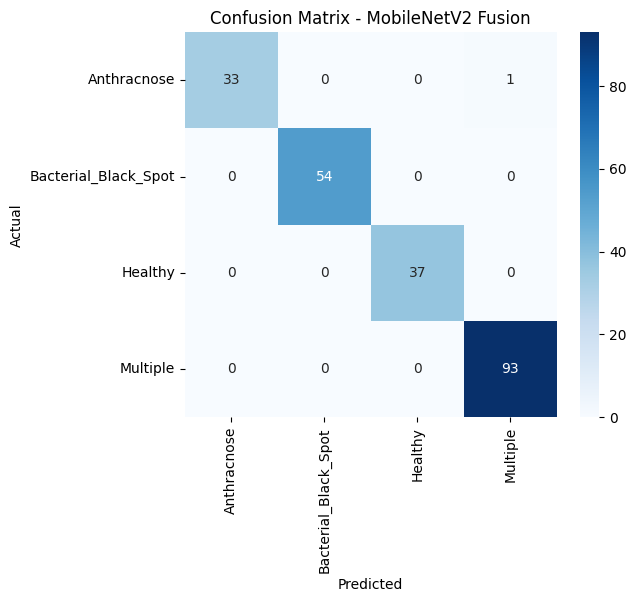

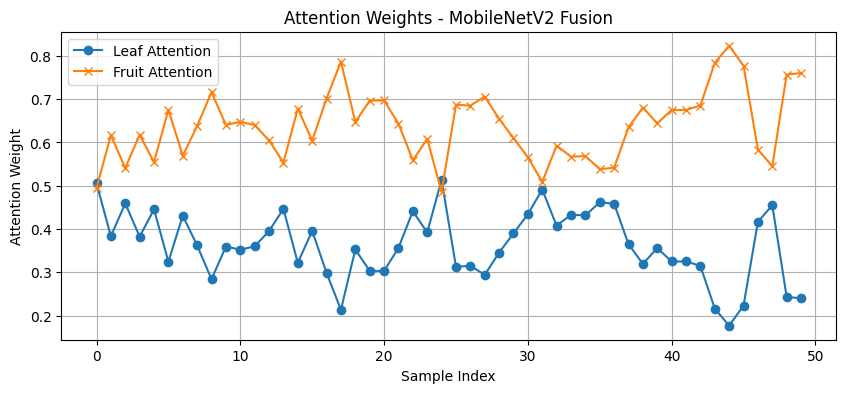

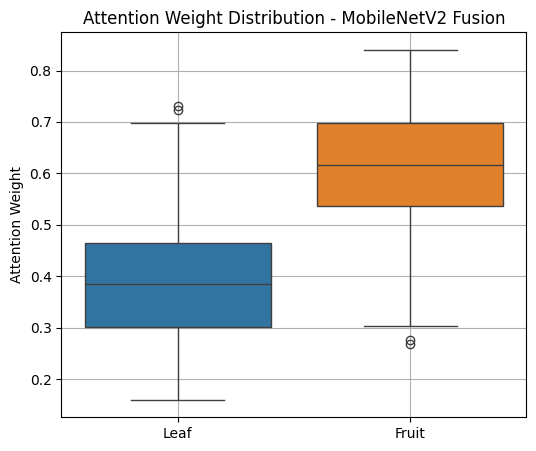

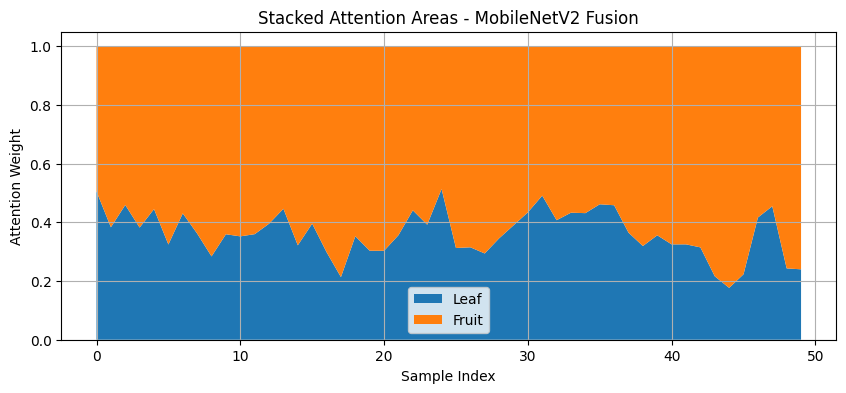

In [ ]:
evaluate_attention_fusion(fusion_model, paired_val_loader, device, class_names, model_name=model_name)
visualize_attention_weights(fusion_model, paired_val_loader, model_name=model_name)
attention_boxplot(fusion_model, paired_val_loader, model_name=model_name)
stacked_attention_plot(fusion_model, paired_val_loader, model_name=model_name)

In [ ]:
leaf_model_path = "/content/drive/MyDrive/MangoProject/Models/best_model.pth"
fruit_model_path = "/content/drive/MyDrive/MangoProject/Models/best_ConNext_fruit.pth"
model_name = "ConvNeXt Fusion"

In [ ]:
# Step 2: Load models
leaf_model = get_model("convnext_tiny").to(device)
fruit_model = get_model("convnext_tiny").to(device)

leaf_model.load_state_dict(torch.load(leaf_model_path, map_location=device))
fruit_model.load_state_dict(torch.load(fruit_model_path, map_location=device))

leaf_model.eval()
fruit_model.eval()

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  w

ConvNeXt(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): LayerNorm2d((96,), eps=1e-06, elementwise_affine=True)
    )
    (1): Sequential(
      (0): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=96, out_features=384, bias=True)
          (4): GELU(approximate='none')
          (5): Linear(in_features=384, out_features=96, bias=True)
          (6): Permute()
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): CNBlock(
        (block): Sequential(
          (0): Conv2d(96, 96, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=96)
          (1): Permute()
          (2): LayerNorm((96,), eps=1e-06, elementwise_affine=True)
          (3): Linear(in_features=

In [ ]:
fusion_model = FusionModel(leaf_model, fruit_model).to(device)


📌 Evaluating Model: ConvNeXt Fusion
✅ Accuracy: 0.9312
🔁 Precision (macro): 0.9240
🔁 Recall (macro): 0.9276
🔁 F1 Score (macro): 0.9176
🧠 Cohen’s Kappa: 0.9027
🧠 Matthews Corrcoef: 0.9066

📊 Classification Report:

                      precision    recall  f1-score   support

         Anthracnose       0.72      0.97      0.82        34
Bacterial_Black_Spot       1.00      0.78      0.88        54
             Healthy       1.00      0.97      0.99        37
            Multiple       0.98      0.99      0.98        93

            accuracy                           0.93       218
           macro avg       0.92      0.93      0.92       218
        weighted avg       0.95      0.93      0.93       218



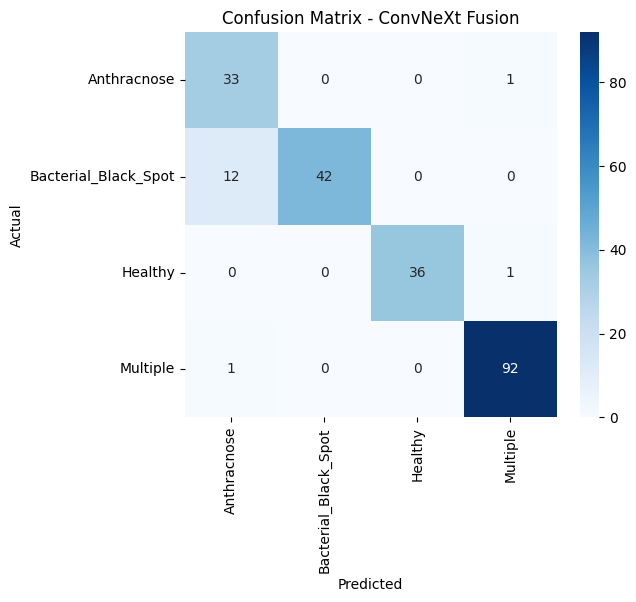

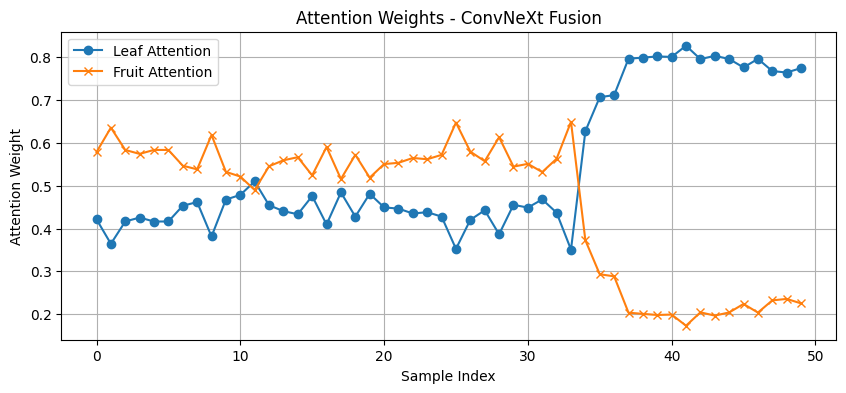

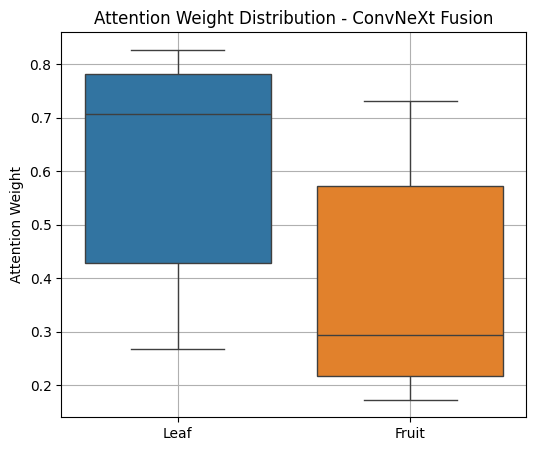

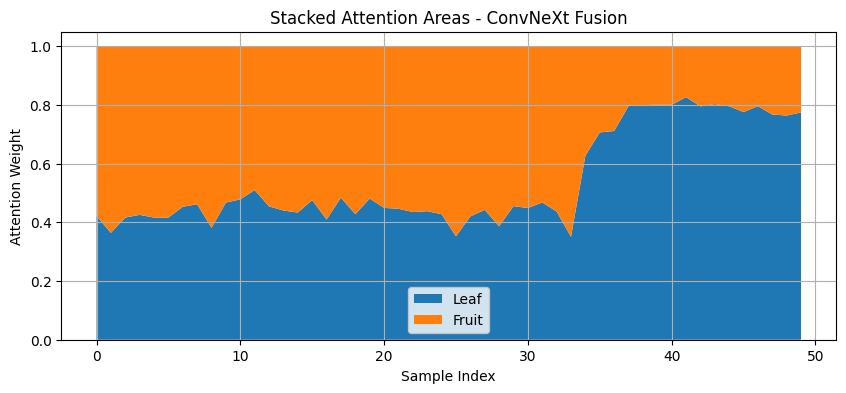

In [ ]:
evaluate_attention_fusion(fusion_model, paired_val_loader, device, class_names, model_name=model_name)
visualize_attention_weights(fusion_model, paired_val_loader, model_name=model_name)
attention_boxplot(fusion_model, paired_val_loader, model_name=model_name)
stacked_attention_plot(fusion_model, paired_val_loader, model_name=model_name)